# Heart Disease Prediction
## Classification Problem using Many More Classification ML Algo to solve it
### Heart Disease are the lead Disease now a Days so, we predict for a Person having Heart Disease or Not by using some existing Medical Features.

## Contain Features are like

#### Numerical Feature
- slope_of_peak_exercise_st_segment 
- resting_blood_pressure 
- chest_pain_type 
- num_major_vessels 
- resting_ekg_results 
- serum_cholesterol_mg_per_dl 
- oldpeak_eq_st_depression 
- age
- max_heart_rate_achieved 

#### Categorical Features
- thal
-

#### Binary Features
- fasting_blood_sugar_gt_120_mg_per_dl 
- sex
- exercise_induced_angina 

# Steps To Predict for the Dataset

### Step 1:
- Import all Library

### Step 2:
- Load the Datasets

### Step 3:
- Basic Checks & Data Understanding

### Step 4:
- Data Cleaning

### Step 5:
- Exploratory Data Analysis(EDA)
- Outlier Handling

### Step 6:
##### Feature Engineering
- Handeling Missing Values
- Check Duplicates
- Handeling Categorical Features
- One-Hot Encoder
- Feature Scaling

### Step 7:
- Separate X and Y

### Step 8:
- Train_test_split

### Step 9:
- Model Building

### Step 10:
- Model Evaluation

### Step 11:
- Model Comparison

### Step 12:
- Hyperparameter Tuning

### Step 13:
- Final Model Selection

### Dtep 14:
- Save the Model

### Step 15:
- Predict New Patient


In [4]:
# Step 1:(Import all Library)

import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

#Train Test Split
from sklearn.model_selection import train_test_split

# Preprocessing
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

#Machine Learning Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier

#PipeLine
from sklearn.pipeline import Pipeline

# Evaluation metrics
from sklearn.metrics import(
accuracy_score,
precision_score,
recall_score,
f1_score,
confusion_matrix,
classification_report,
roc_auc_score,
RocCurveDisplay
)

# Hyperparamater Tuning
from sklearn.model_selection import GridSearchCV

# Save Model
import joblib

# Warnings

import warnings
warnings.filterwarnings('ignore')

In [5]:
# Step 2:(Load Dataset)

d1 = pd.read_csv("C:/Users/rites/Desktop/DataMiteCaptionProject/values.csv")

d2 = pd.read_csv("C:/Users/rites/Desktop/DataMiteCaptionProject/labels.csv")

In [6]:
# Merging the 2 Dataset with the common column name patient_id

df = pd.merge(
    d1,
    d2,
    on = 'patient_id',
    how = "inner"
)

df

,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
0,0z64un,1,normal,128,2,0,0,2,308,0.0,1,45,170,0,0
1,ryoo3j,2,normal,110,3,0,0,0,214,1.6,0,54,158,0,0
2,yt1s1x,1,normal,125,4,3,0,2,304,0.0,1,77,162,1,1
3,l2xjde,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0,1
4,oyt4ek,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175,5qfar3,2,reversible_defect,125,4,2,1,0,254,0.2,1,67,163,0,1
176,2s2b1f,2,normal,180,4,0,0,1,327,3.4,0,55,117,1,1
177,nsd00i,2,reversible_defect,125,3,0,0,0,309,1.8,1,64,131,1,1
178,0xw93k,1,normal,124,3,2,1,0,255,0.0,1,48,175,0,0


In [7]:
# Step 3:(Basic Checks & Data understanding)

df.head()

,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
0,0z64un,1,normal,128,2,0,0,2,308,0.0,1,45,170,0,0
1,ryoo3j,2,normal,110,3,0,0,0,214,1.6,0,54,158,0,0
2,yt1s1x,1,normal,125,4,3,0,2,304,0.0,1,77,162,1,1
3,l2xjde,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0,1
4,oyt4ek,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0,0


In [8]:
df.tail()

,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
175,5qfar3,2,reversible_defect,125,4,2,1,0,254,0.2,1,67,163,0,1
176,2s2b1f,2,normal,180,4,0,0,1,327,3.4,0,55,117,1,1
177,nsd00i,2,reversible_defect,125,3,0,0,0,309,1.8,1,64,131,1,1
178,0xw93k,1,normal,124,3,2,1,0,255,0.0,1,48,175,0,0
179,2nx10r,1,normal,160,3,1,0,0,201,0.0,0,54,163,0,0


In [9]:
df.shape

(180, 15)

In [10]:
df.columns

Index(['patient_id', 'slope_of_peak_exercise_st_segment', 'thal',
       'resting_blood_pressure', 'chest_pain_type', 'num_major_vessels',
       'fasting_blood_sugar_gt_120_mg_per_dl', 'resting_ekg_results',
       'serum_cholesterol_mg_per_dl', 'oldpeak_eq_st_depression', 'sex', 'age',
       'max_heart_rate_achieved', 'exercise_induced_angina',
       'heart_disease_present'],
      dtype='object')

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 15 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   patient_id                            180 non-null    object 
 1   slope_of_peak_exercise_st_segment     180 non-null    int64  
 2   thal                                  180 non-null    object 
 3   resting_blood_pressure                180 non-null    int64  
 4   chest_pain_type                       180 non-null    int64  
 5   num_major_vessels                     180 non-null    int64  
 6   fasting_blood_sugar_gt_120_mg_per_dl  180 non-null    int64  
 7   resting_ekg_results                   180 non-null    int64  
 8   serum_cholesterol_mg_per_dl           180 non-null    int64  
 9   oldpeak_eq_st_depression              180 non-null    float64
 10  sex                                   180 non-null    int64  
 11  age                

In [12]:
df.describe()

,slope_of_peak_exercise_st_segment,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
count,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000
mean,1.550000,131.311111,3.155556,0.694444,0.161111,1.050000,249.211111,1.010000,0.688889,54.811111,149.483333,0.316667,0.444444
std,0.618838,17.010443,0.938454,0.969347,0.368659,0.998742,52.717969,1.121357,0.464239,9.334737,22.063513,0.466474,0.498290
min,1.000000,94.000000,1.000000,0.000000,0.000000,0.000000,126.000000,0.000000,0.000000,29.000000,96.000000,0.000000,0.000000
25%,1.000000,120.000000,3.000000,0.000000,0.000000,0.000000,213.750000,0.000000,0.000000,48.000000,132.000000,0.000000,0.000000
50%,1.000000,130.000000,3.000000,0.000000,0.000000,2.000000,245.500000,0.800000,1.000000,55.000000,152.000000,0.000000,0.000000
75%,2.000000,140.000000,4.000000,1.000000,0.000000,2.000000,281.250000,1.600000,1.000000,62.000000,166.250000,1.000000,1.000000
max,3.000000,180.000000,4.000000,3.000000,1.000000,2.000000,564.000000,6.200000,1.000000,77.000000,202.000000,1.000000,1.000000


In [13]:
df['heart_disease_present'].value_counts()

heart_disease_present
0    100
1     80
Name: count, dtype: int64

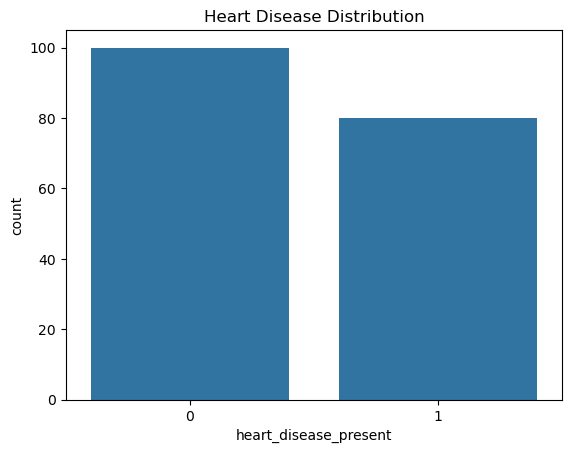

In [14]:
# Target Distribution Visulaization

sns.countplot(x = "heart_disease_present", data = df)
plt.title("Heart Disease Distribution")
plt.show()

In [15]:
# Step 4:(Data Cleaning)
df.isnull().sum()

patient_id                              0
slope_of_peak_exercise_st_segment       0
thal                                    0
resting_blood_pressure                  0
chest_pain_type                         0
num_major_vessels                       0
fasting_blood_sugar_gt_120_mg_per_dl    0
resting_ekg_results                     0
serum_cholesterol_mg_per_dl             0
oldpeak_eq_st_depression                0
sex                                     0
age                                     0
max_heart_rate_achieved                 0
exercise_induced_angina                 0
heart_disease_present                   0
dtype: int64

In [16]:
df.duplicated().sum()

0

In [17]:
# Step 5: EDA


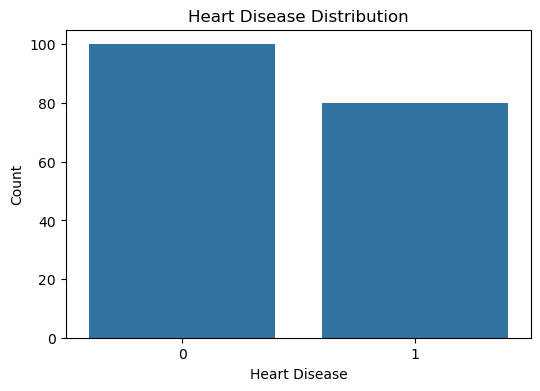

In [18]:
# Target Distribution
# 0 Refers no Disease and 1 Refers Disease
plt.figure(figsize = (6,4))

sns.countplot(x = "heart_disease_present", data = df)

plt.title("Heart Disease Distribution")
plt.xlabel("Heart Disease")
plt.ylabel("Count")

plt.show()

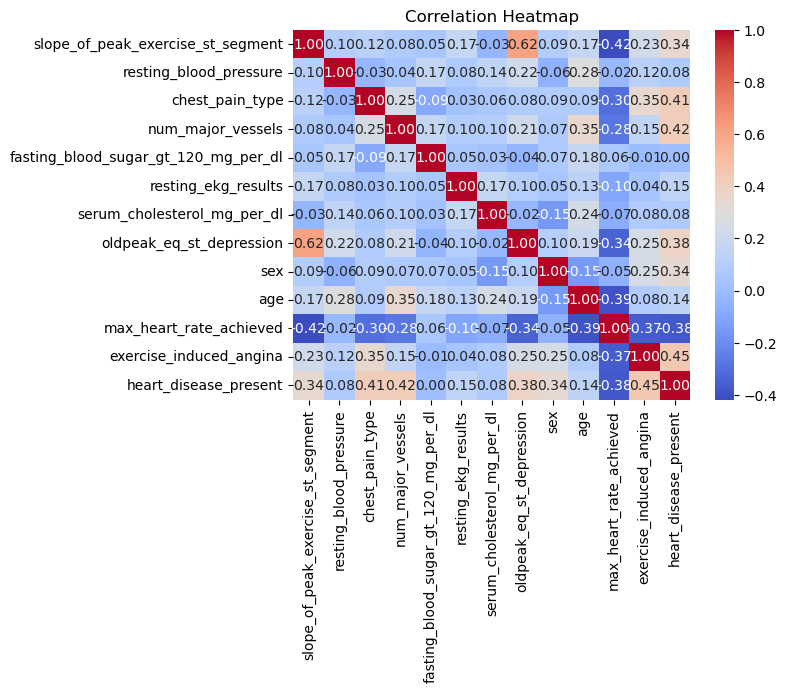

In [19]:
# Correlation HeatMap
sns.heatmap(
    df.drop(columns = ["patient_id"], errors = "ignore").corr(numeric_only = True),
    annot = True,
    cmap = 'coolwarm',
    fmt = '.2f'
)

plt.title("Correlation Heatmap")

plt.show()

In [20]:
# Univariate Analysis
df.columns


Index(['patient_id', 'slope_of_peak_exercise_st_segment', 'thal',
       'resting_blood_pressure', 'chest_pain_type', 'num_major_vessels',
       'fasting_blood_sugar_gt_120_mg_per_dl', 'resting_ekg_results',
       'serum_cholesterol_mg_per_dl', 'oldpeak_eq_st_depression', 'sex', 'age',
       'max_heart_rate_achieved', 'exercise_induced_angina',
       'heart_disease_present'],
      dtype='object')

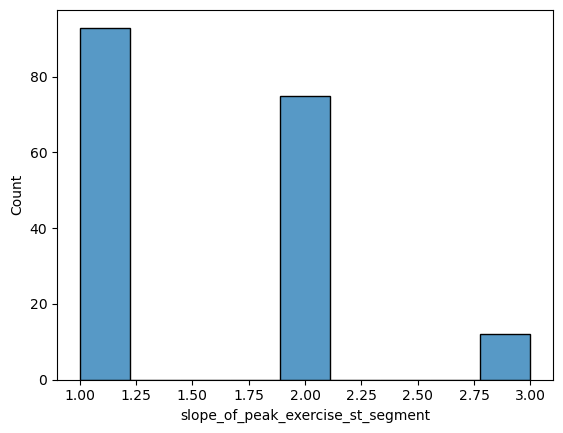

In [21]:
sns.histplot(data = df, x = "slope_of_peak_exercise_st_segment")
plt.show()

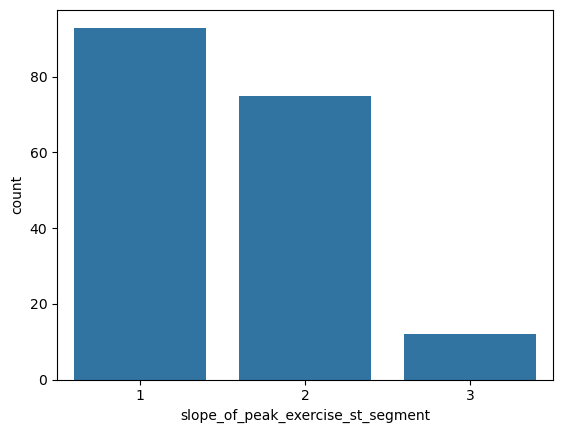

In [22]:
sns.countplot(data = df, x = "slope_of_peak_exercise_st_segment")
plt.show()

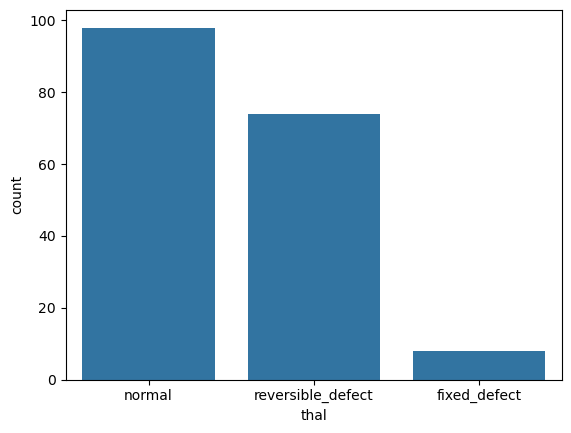

In [23]:
# thal
sns.countplot(data = df, x = "thal")
plt.show()

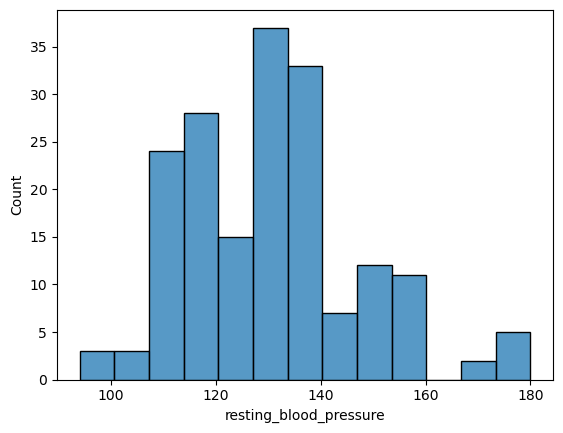

In [24]:
# resting_blood_pressure
sns.histplot(data = df, x = "resting_blood_pressure")
plt.show()

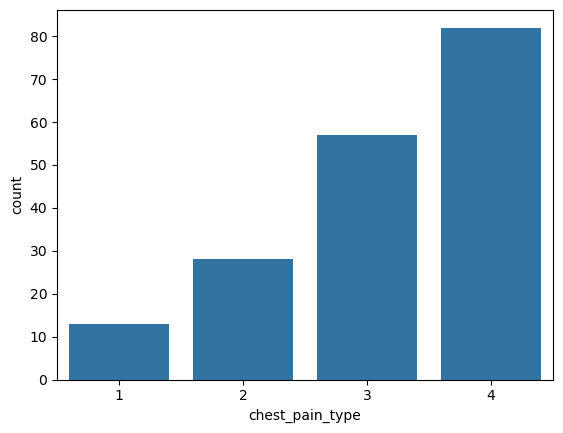

In [25]:
# chest_pain_type
sns.countplot(data = df, x = "chest_pain_type")
plt.show()

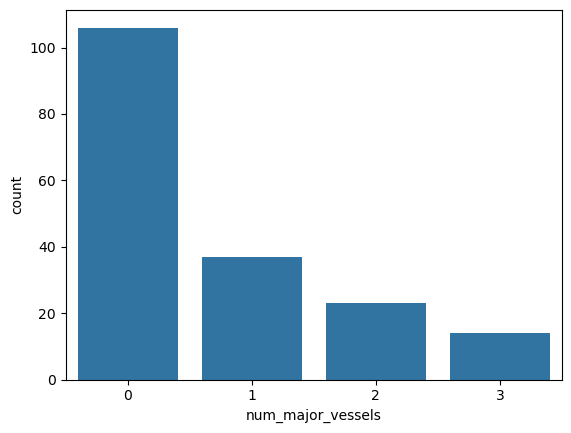

In [26]:
# num_major_vessels
sns.countplot(data = df, x = "num_major_vessels")
plt.show()

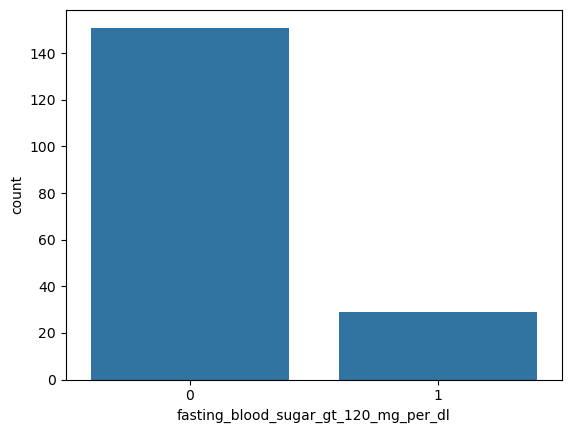

In [27]:
# fasting_blood_sugar_gt_120_mg_per_dl
sns.countplot(data = df, x = "fasting_blood_sugar_gt_120_mg_per_dl")
plt.show()

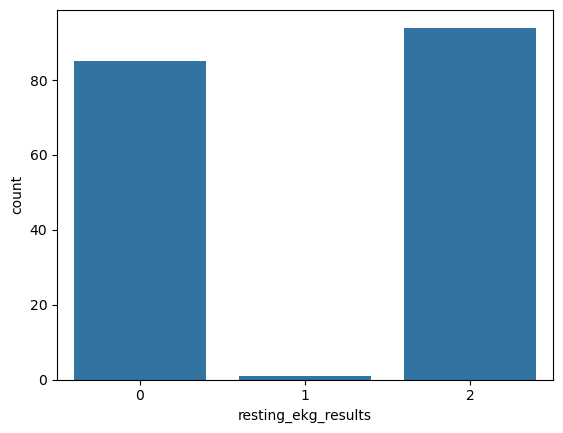

In [28]:
# resting_ekg_results
sns.countplot(data = df, x= "resting_ekg_results")
plt.show()

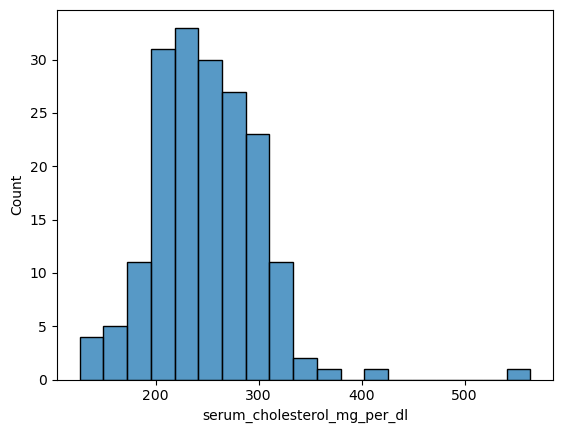

In [29]:
#serum_cholesterol_mg_per_dl
sns.histplot(data = df, x= "serum_cholesterol_mg_per_dl")
plt.show()

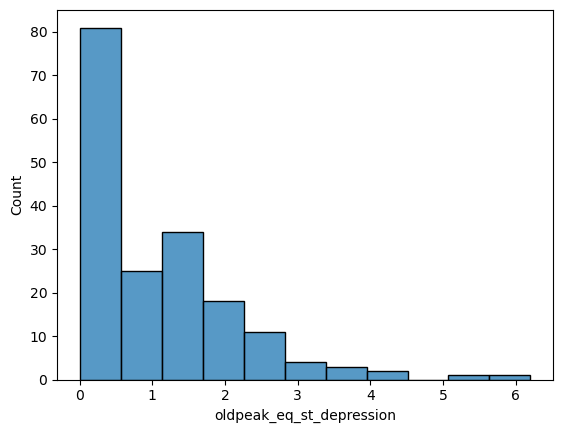

In [30]:
# oldpeak_eq_st_depression
sns.histplot(data = df, x= "oldpeak_eq_st_depression")
plt.show()

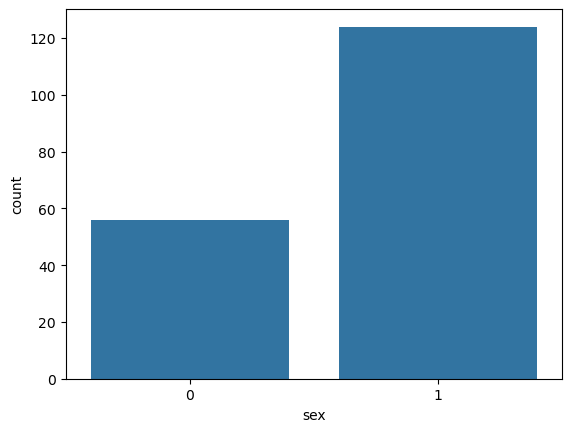

In [31]:
# sex
sns.countplot(data = df, x= "sex")
plt.show()

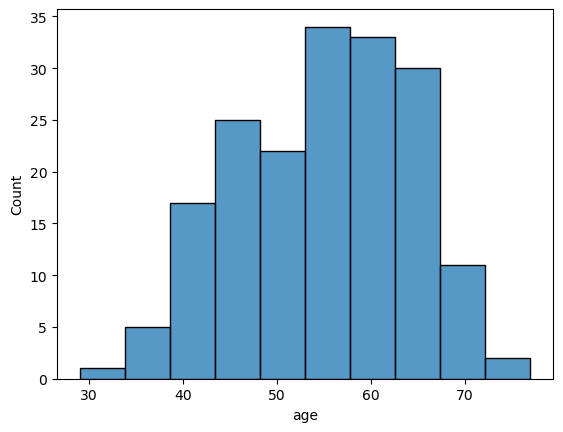

In [32]:
# age
sns.histplot(data = df, x= "age")
plt.show()

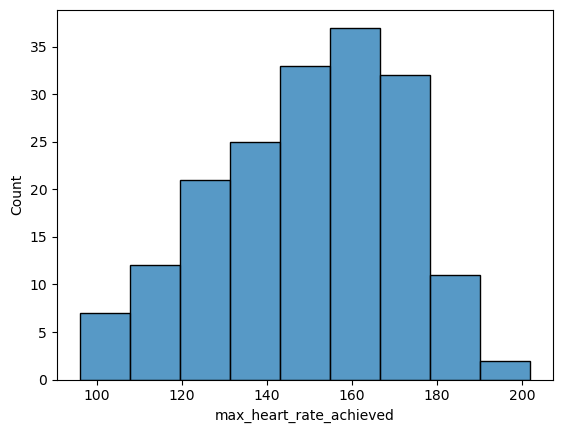

In [33]:
# max_heart_rate_achieved

'''Max Heart Rate Achieved means the maximum number of times a person's heart beats per minute (BPM) during exercise or a stress test.'''
sns.histplot(data = df, x= "max_heart_rate_achieved")
plt.show()

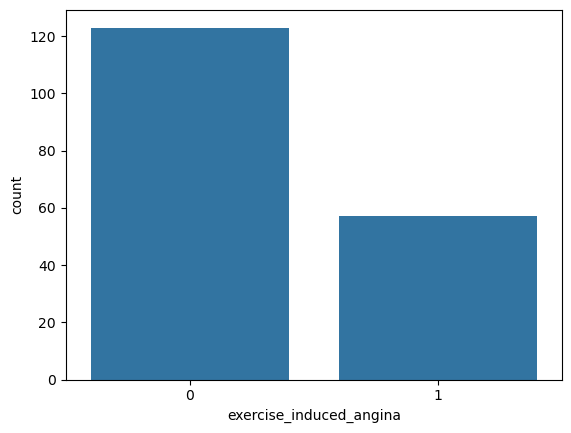

In [34]:
# exercise_induced_angina
'''
Exercise-Induced Angina means chest pain or discomfort that occurs during physical activity or exercise because the heart muscle is not getting enough oxygen-rich blood.
'''
sns.countplot(data = df, x= "exercise_induced_angina")
plt.show()

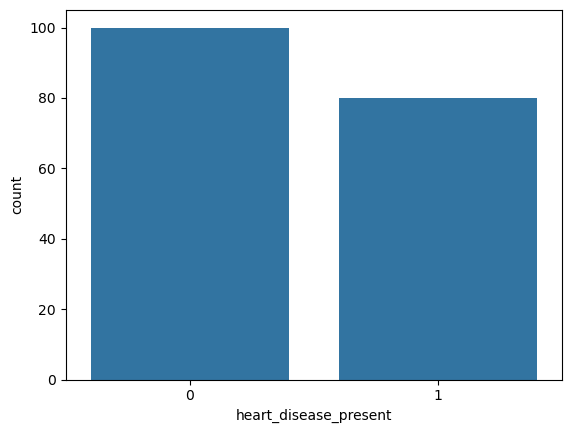

In [35]:
# heart_disease_present
sns.countplot(data = df, x = "heart_disease_present")
plt.show()

In [36]:
# Bivariate Analysis
df.columns


Index(['patient_id', 'slope_of_peak_exercise_st_segment', 'thal',
       'resting_blood_pressure', 'chest_pain_type', 'num_major_vessels',
       'fasting_blood_sugar_gt_120_mg_per_dl', 'resting_ekg_results',
       'serum_cholesterol_mg_per_dl', 'oldpeak_eq_st_depression', 'sex', 'age',
       'max_heart_rate_achieved', 'exercise_induced_angina',
       'heart_disease_present'],
      dtype='object')

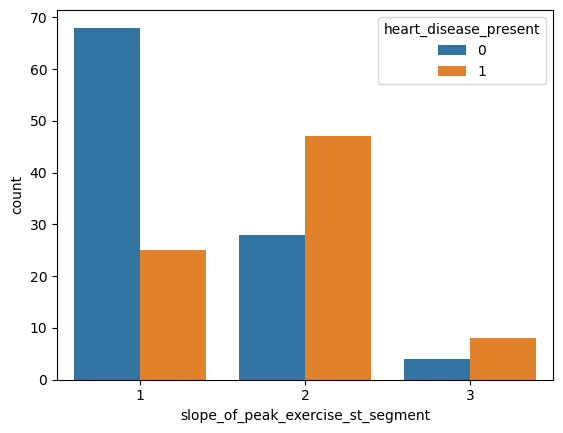

In [37]:
# slope_of_peak_exercise_st_segment

sns.countplot(x = "slope_of_peak_exercise_st_segment", hue = "heart_disease_present", data = df)
plt.show()


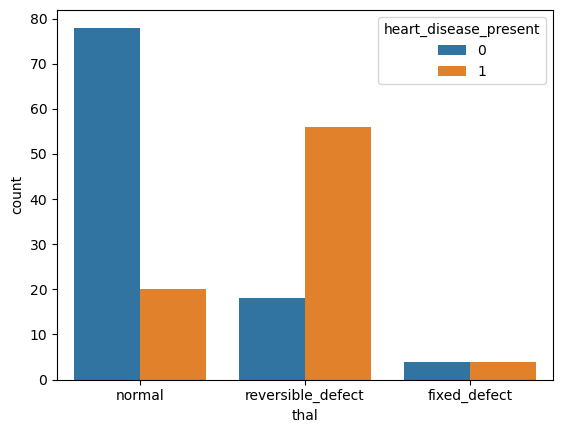

In [38]:
# thal

sns.countplot(data = df ,x = "thal",hue = "heart_disease_present")
plt.show()

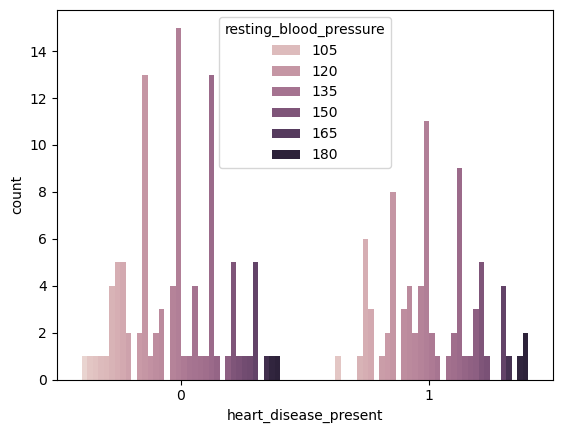

In [39]:
# resting_blood_pressure
sns.countplot(data = df, x = "heart_disease_present",hue = "resting_blood_pressure")
plt.show()

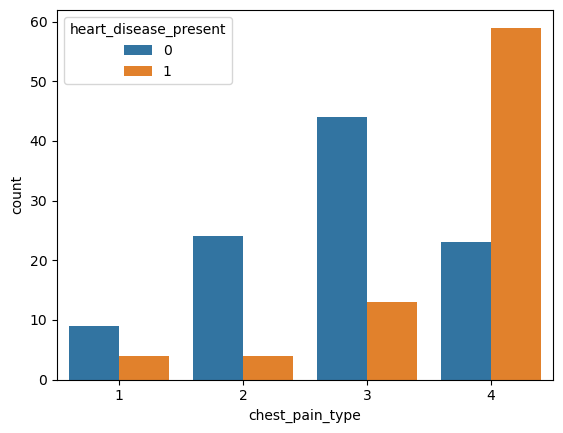

In [40]:
# chest_pain_type
sns.countplot(data = df, x = "chest_pain_type", hue = "heart_disease_present")
plt.show()

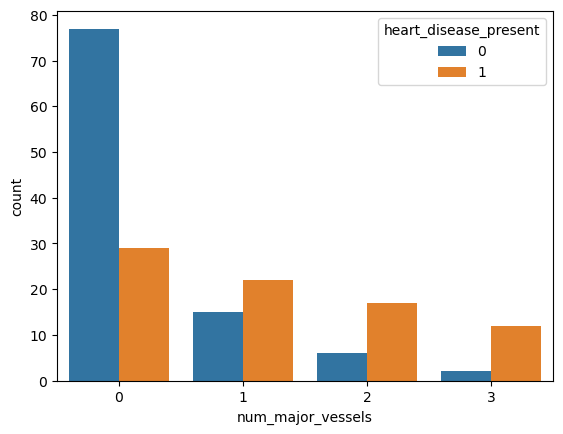

In [41]:
# num_major_vessels
'''num_major_vessels means the number of major blood vessels (coronary arteries) visible using a special imaging test called fluoroscopy'''

sns.countplot(data = df, x = "num_major_vessels", hue = "heart_disease_present")
plt.show()

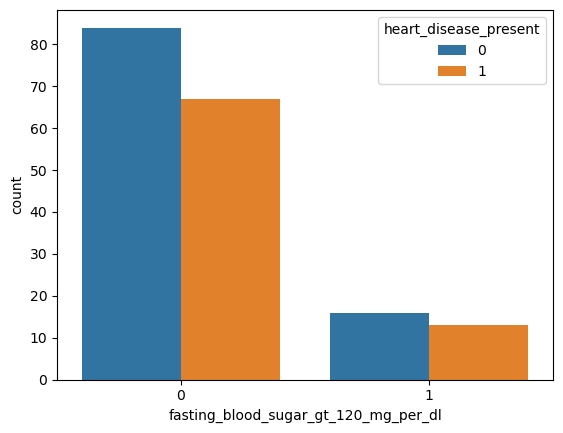

In [42]:
# fasting_blood_sugar_gt_120_mg_per_dl

sns.countplot(data = df, x = "fasting_blood_sugar_gt_120_mg_per_dl", hue = "heart_disease_present")
plt.show()

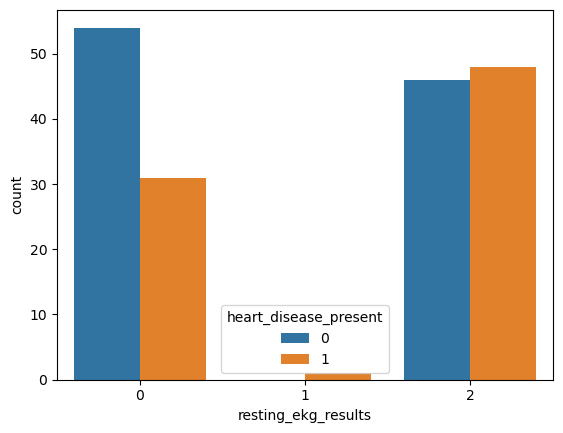

In [43]:
# resting_ekg_results
sns.countplot(data = df , x= "resting_ekg_results", hue = "heart_disease_present")
plt.show()

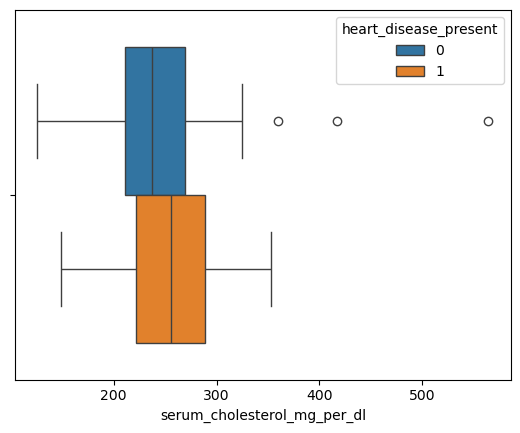

In [44]:
# serum_cholesterol_mg_per_dl
sns.boxplot(data = df , x= "serum_cholesterol_mg_per_dl", hue = "heart_disease_present")
plt.show()

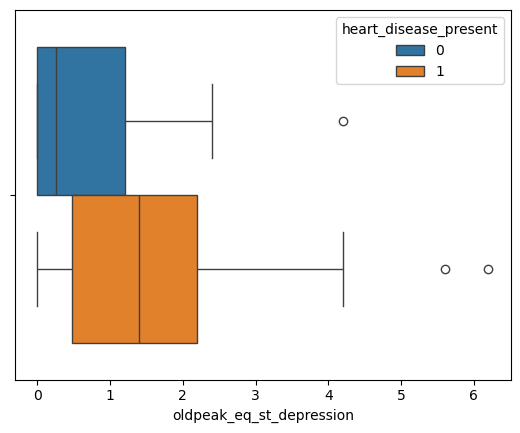

In [45]:
# oldpeak_eq_st_depression
sns.boxplot(data = df , x= "oldpeak_eq_st_depression", hue = "heart_disease_present")
plt.show()

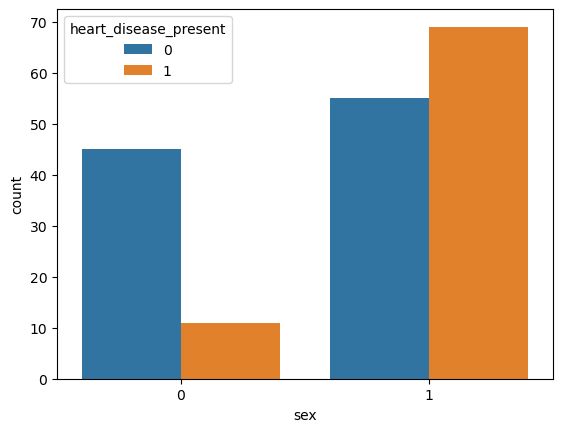

In [46]:
# sex

sns.countplot(data = df, x = "sex", hue = "heart_disease_present")
plt.show()

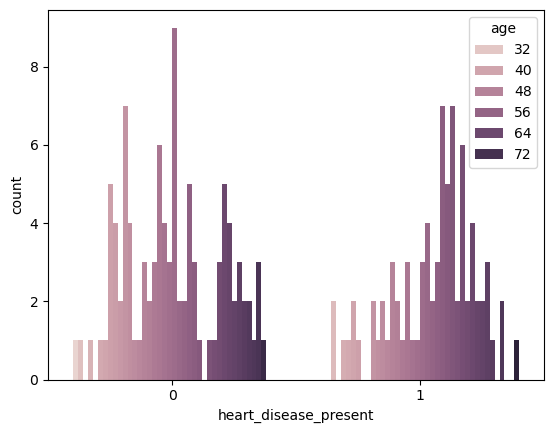

In [47]:
# age

sns.countplot(data = df, x = "heart_disease_present", hue = "age")
plt.show()

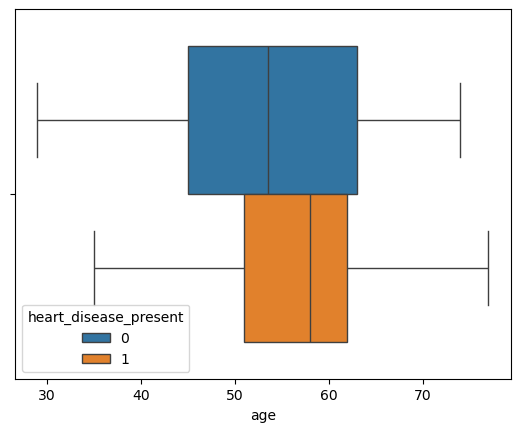

In [48]:
sns.boxplot(data = df, x = "age", hue = "heart_disease_present")
plt.show()

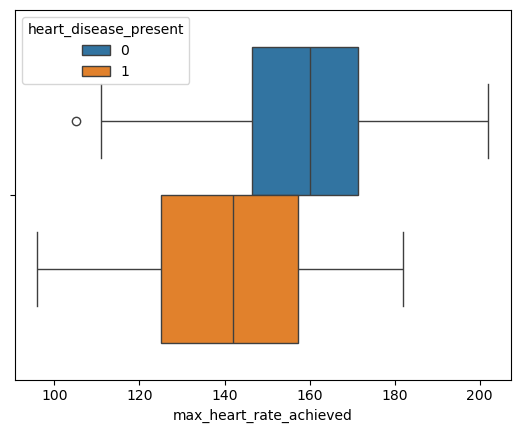

In [49]:
# max_heart_rate_achieved

sns.boxplot(data = df, x = "max_heart_rate_achieved",hue = "heart_disease_present")
plt.show()

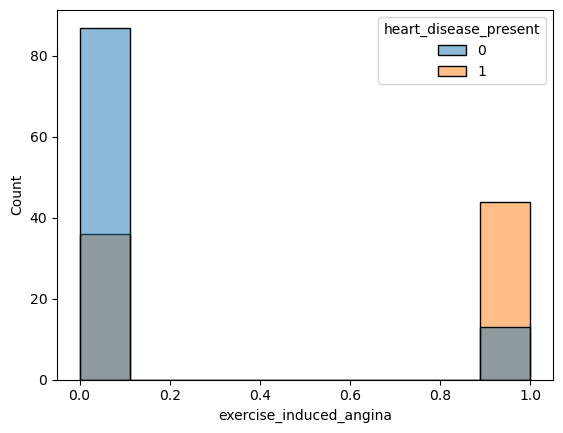

In [50]:
# exercise_induced_angina

sns.histplot(data = df, x = "exercise_induced_angina",hue = "heart_disease_present")
plt.show()

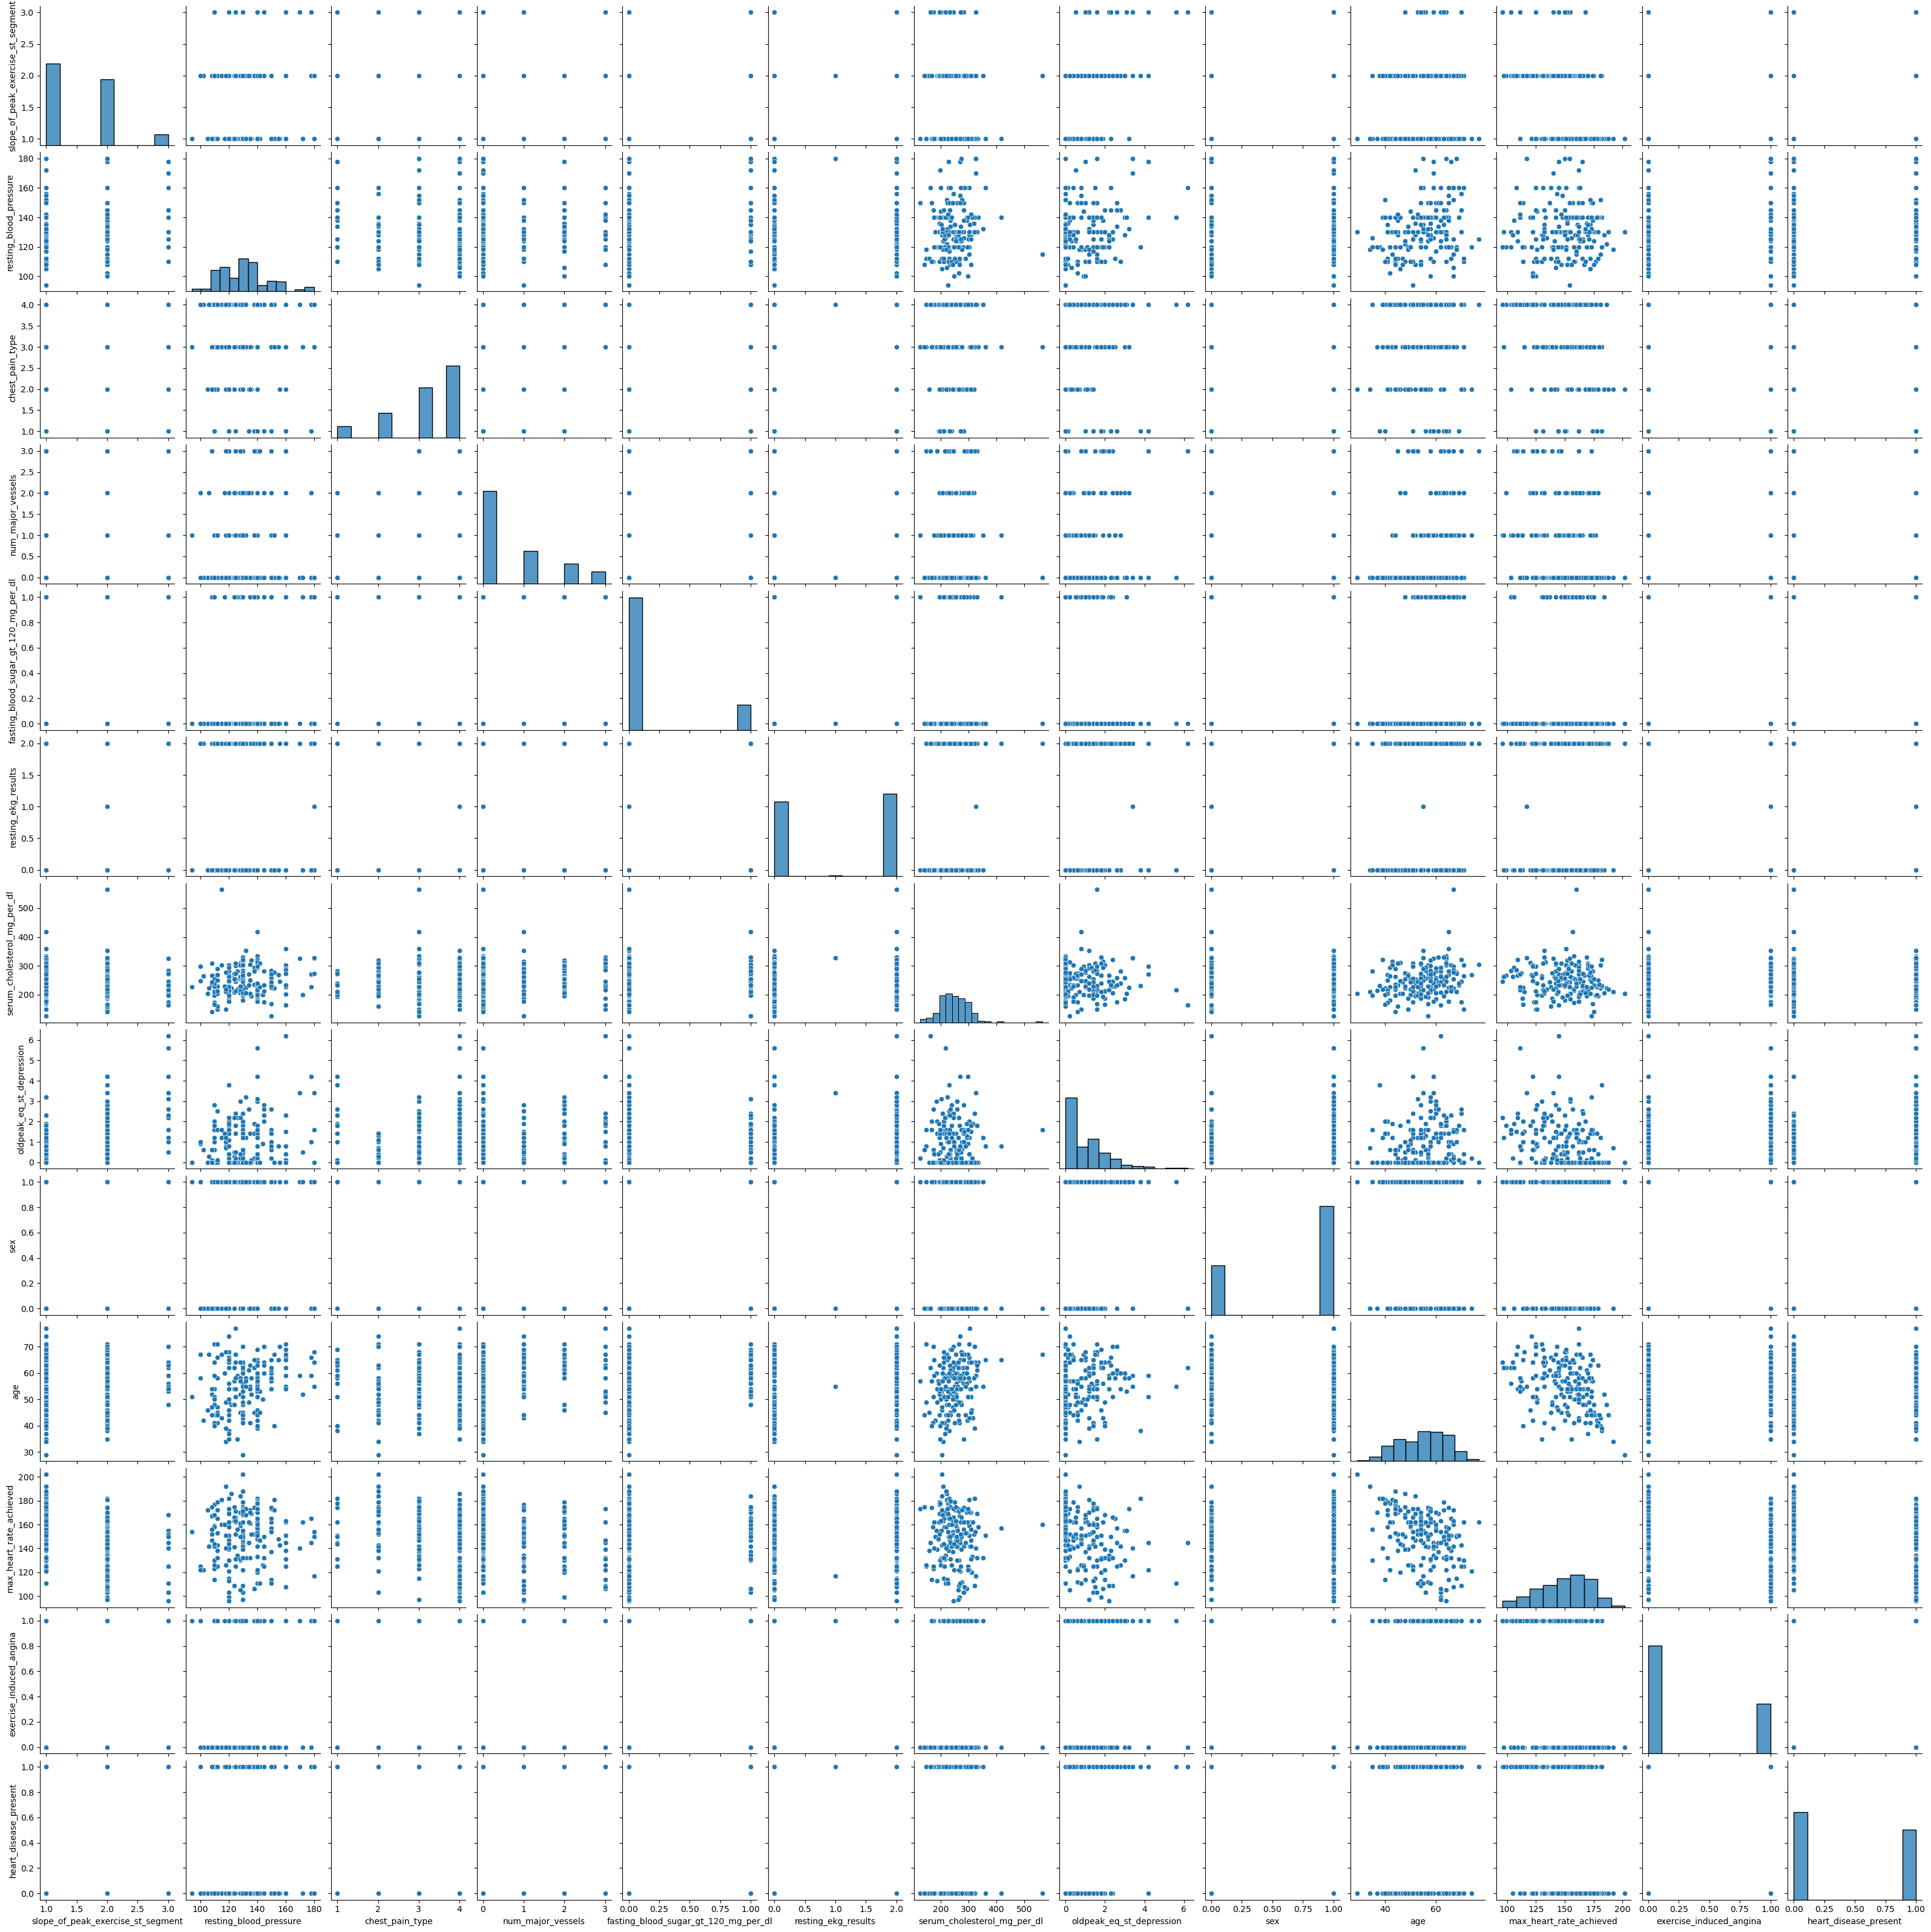

In [51]:
# Multivariate Analysis

sns.pairplot(data = df)
plt.show()


# Outlier Detect & Handeling

In [52]:
# Check outliers one by one
## 1st Identify the all Numerical Values

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 15 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   patient_id                            180 non-null    object 
 1   slope_of_peak_exercise_st_segment     180 non-null    int64  
 2   thal                                  180 non-null    object 
 3   resting_blood_pressure                180 non-null    int64  
 4   chest_pain_type                       180 non-null    int64  
 5   num_major_vessels                     180 non-null    int64  
 6   fasting_blood_sugar_gt_120_mg_per_dl  180 non-null    int64  
 7   resting_ekg_results                   180 non-null    int64  
 8   serum_cholesterol_mg_per_dl           180 non-null    int64  
 9   oldpeak_eq_st_depression              180 non-null    float64
 10  sex                                   180 non-null    int64  
 11  age                

In [53]:
num_cols = df.select_dtypes(include = "number").columns
print(num_cols)

Index(['slope_of_peak_exercise_st_segment', 'resting_blood_pressure',
       'chest_pain_type', 'num_major_vessels',
       'fasting_blood_sugar_gt_120_mg_per_dl', 'resting_ekg_results',
       'serum_cholesterol_mg_per_dl', 'oldpeak_eq_st_depression', 'sex', 'age',
       'max_heart_rate_achieved', 'exercise_induced_angina',
       'heart_disease_present'],
      dtype='object')


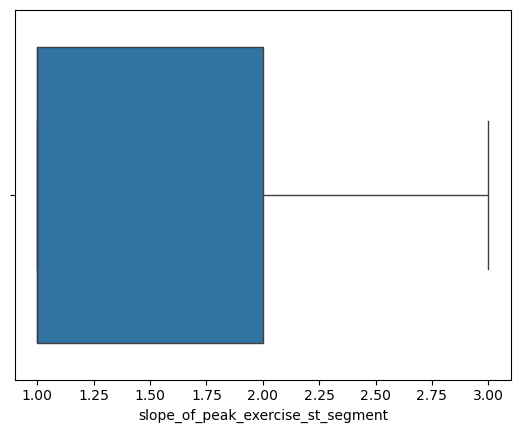

In [54]:
# slope_of_peak_exercise_st_segment
sns.boxplot(data = df, x= "slope_of_peak_exercise_st_segment")
plt.show()

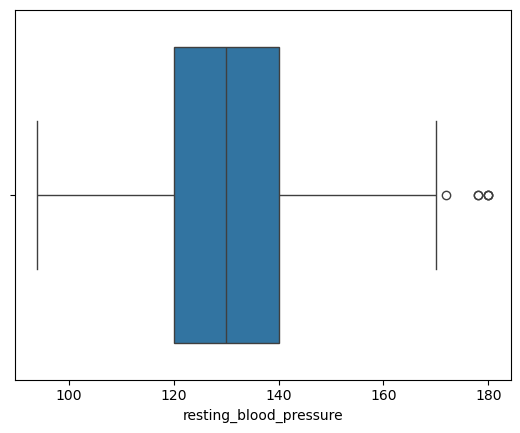

In [55]:
# resting_blood_pressure
sns.boxplot(data = df, x= "resting_blood_pressure")
plt.show()

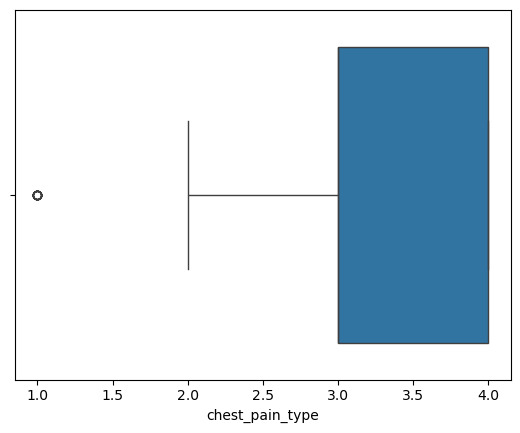

In [56]:
# chest_pain_type
sns.boxplot(data = df, x= "chest_pain_type")
plt.show()

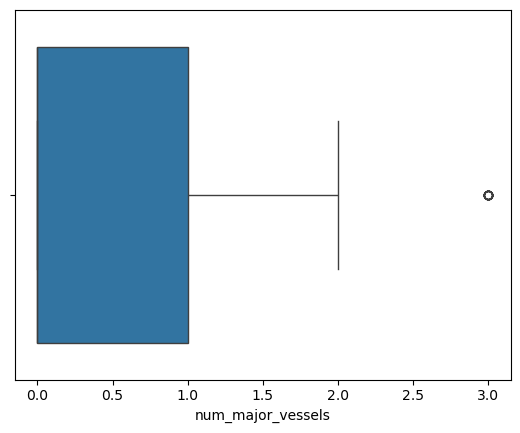

In [57]:
# num_major_vessels
sns.boxplot(data = df, x= "num_major_vessels")
plt.show()

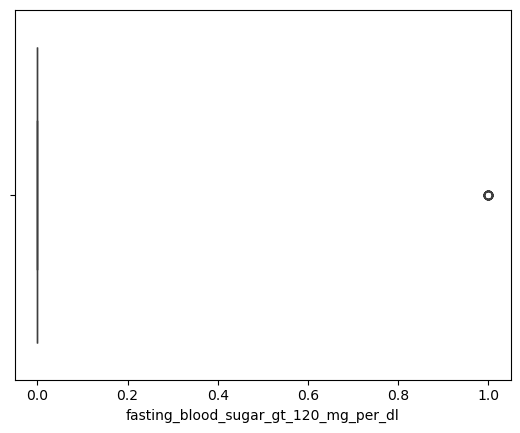

In [58]:
# fasting_blood_sugar_gt_120_mg_per_dl
sns.boxplot(data = df, x= "fasting_blood_sugar_gt_120_mg_per_dl")
plt.show()

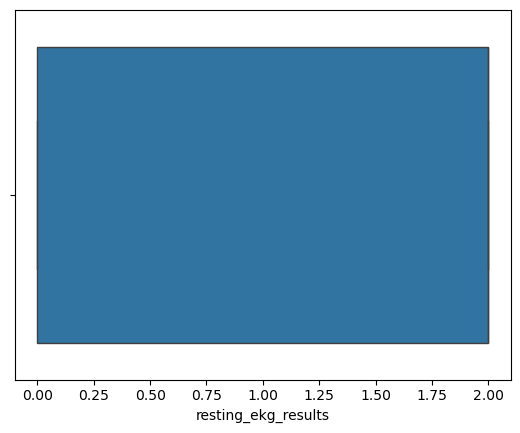

In [59]:
# resting_ekg_results
sns.boxplot(data = df, x= "resting_ekg_results")
plt.show()

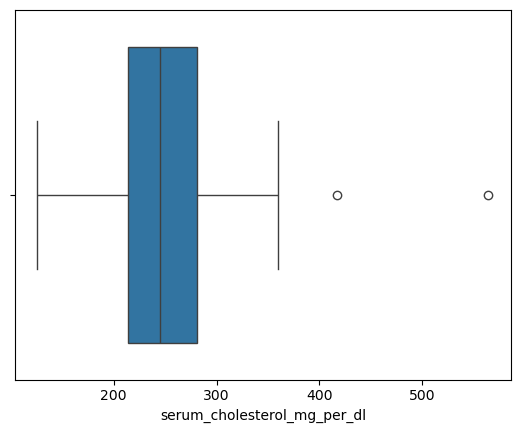

In [60]:
# serum_cholesterol_mg_per_dl
sns.boxplot(data = df, x= "serum_cholesterol_mg_per_dl")
plt.show()

In [61]:
df['serum_cholesterol_mg_per_dl'].max()

564

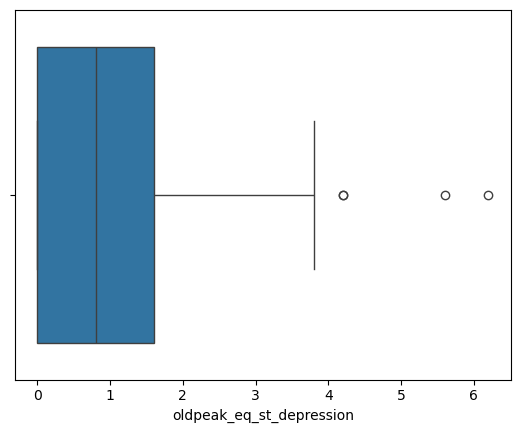

In [62]:
# oldpeak_eq_st_depression
sns.boxplot(data = df, x= "oldpeak_eq_st_depression")
plt.show()

In [63]:
df['oldpeak_eq_st_depression'].max()

6.2

In [64]:
df[df['oldpeak_eq_st_depression'] > 6]

,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
162,usnkhx,3,reversible_defect,160,4,3,0,2,164,6.2,0,62,145,0,1


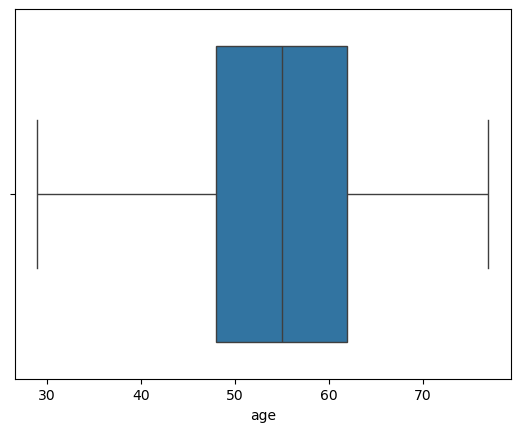

In [65]:
sns.boxplot(data = df, x = "age")
plt.show()

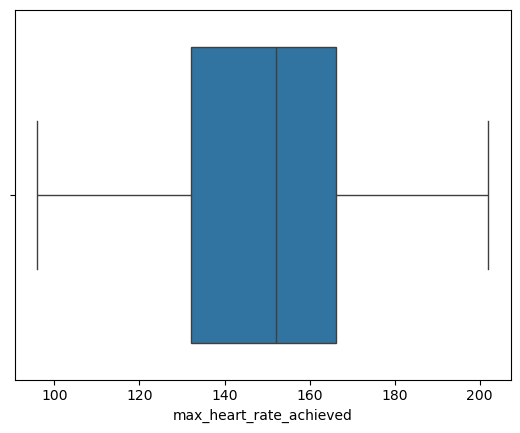

In [66]:
# max_heart_rate_achieved
sns.boxplot(data = df, x = "max_heart_rate_achieved")
plt.show()

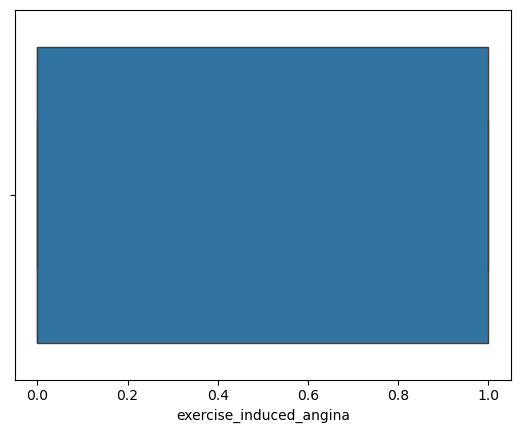

In [67]:
# exercise_induced_angina
sns.boxplot(data = df, x = "exercise_induced_angina")
plt.show()

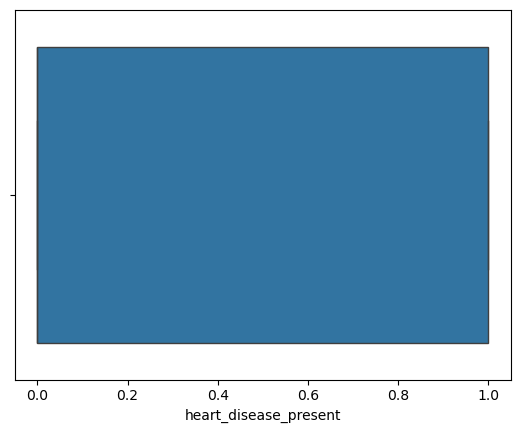

In [68]:
# heart_disease_present

sns.boxplot(data = df, x = "heart_disease_present")
plt.show()

In [69]:
# No need to Handel any Outlier Because all max values or min values are clinically acceptable.

In [70]:
'''Step 6:
Feature Engineering
Handeling Missing Values
Check Duplicates
Handeling Categorical Features
One-Hot Encoder
Feature Scaling'''



'Step 6:\nFeature Engineering\nHandeling Missing Values\nCheck Duplicates\nHandeling Categorical Features\nOne-Hot Encoder\nFeature Scaling'

In [71]:
#Check & Handeling Missing Values
df.isnull().sum()

patient_id                              0
slope_of_peak_exercise_st_segment       0
thal                                    0
resting_blood_pressure                  0
chest_pain_type                         0
num_major_vessels                       0
fasting_blood_sugar_gt_120_mg_per_dl    0
resting_ekg_results                     0
serum_cholesterol_mg_per_dl             0
oldpeak_eq_st_depression                0
sex                                     0
age                                     0
max_heart_rate_achieved                 0
exercise_induced_angina                 0
heart_disease_present                   0
dtype: int64

In [72]:
#Check Duplicates
df.duplicated().sum()

0

In [73]:
# Categorical Features
cat_cols = df.select_dtypes(include = ['object','category']).columns
print(cat_cols)

Index(['patient_id', 'thal'], dtype='object')


In [74]:
# Numerical Features

num_cols = df.select_dtypes(include = ['number']).columns
print(num_cols)

Index(['slope_of_peak_exercise_st_segment', 'resting_blood_pressure',
       'chest_pain_type', 'num_major_vessels',
       'fasting_blood_sugar_gt_120_mg_per_dl', 'resting_ekg_results',
       'serum_cholesterol_mg_per_dl', 'oldpeak_eq_st_depression', 'sex', 'age',
       'max_heart_rate_achieved', 'exercise_induced_angina',
       'heart_disease_present'],
      dtype='object')


In [75]:
# One-hot Encoding(nominal) for categorical data= thal,slope_of_peak_exercise_st_segment,chest_pain_type,resting_ekg_results,
# then scaling the numerical features

In [76]:
df.head(5)

,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
0,0z64un,1,normal,128,2,0,0,2,308,0.0,1,45,170,0,0
1,ryoo3j,2,normal,110,3,0,0,0,214,1.6,0,54,158,0,0
2,yt1s1x,1,normal,125,4,3,0,2,304,0.0,1,77,162,1,1
3,l2xjde,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0,1
4,oyt4ek,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0,0


In [77]:
df['num_major_vessels'].mean()

0.6944444444444444

In [78]:
df['heart_disease_present'].max()

1

In [79]:
# Train test

x = df.drop(columns=['heart_disease_present', 'patient_id'])
y = df['heart_disease_present']



In [80]:
x.head(5)

,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina
0,1,normal,128,2,0,0,2,308,0.0,1,45,170,0
1,2,normal,110,3,0,0,0,214,1.6,0,54,158,0
2,1,normal,125,4,3,0,2,304,0.0,1,77,162,1
3,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0
4,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0


In [81]:
y.head(5)

0    0
1    0
2    1
3    1
4    0
Name: heart_disease_present, dtype: int64

In [82]:
## train_test_split

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size = 0.2,random_state = 42,stratify=y)

print("Training data:",x_train.shape)
print("Testing data:",x_test.shape)

Training data: (144, 13)
Testing data: (36, 13)


In [83]:



### Define Categorical Columns

cat_cols = [

    'thal',
    'slope_of_peak_exercise_st_segment',
    'chest_pain_type',
    'resting_ekg_results'
    
]


### Define Numerical Columns

num_cols = [

    'resting_blood_pressure',
    'serum_cholesterol_mg_per_dl',
    'age',
    'oldpeak_eq_st_depression',
    'max_heart_rate_achieved',
    'num_major_vessels'
]

In [84]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(
            drop='first',
            handle_unknown='ignore'
        ), cat_cols)
    ],
    remainder='passthrough'
)

In [85]:

models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    'SVM': SVC(
        probability=True,
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        random_state=42
    )
}

pipelines = {}

for name, model in models.items():

    pipelines[name] = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

print("All pipelines created successfully!")

All pipelines created successfully!


In [86]:
for name, pipeline in pipelines.items():

    pipeline.fit(x_train, y_train)

    print(f"{name} trained successfully!")

Logistic Regression trained successfully!
SVM trained successfully!
Random Forest trained successfully!


In [87]:
preprocessor

ColumnTransformer(remainder='passthrough',
                  transformers=[('num', StandardScaler(),
                                 ['resting_blood_pressure',
                                  'serum_cholesterol_mg_per_dl', 'age',
                                  'oldpeak_eq_st_depression',
                                  'max_heart_rate_achieved',
                                  'num_major_vessels']),
                                ('cat',
                                 OneHotEncoder(drop='first',
                                               handle_unknown='ignore'),
                                 ['thal', 'slope_of_peak_exercise_st_segment',
                                  'chest_pain_type', 'resting_ekg_results'])])

In [100]:
models

{'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
 'SVM': SVC(probability=True, random_state=42),
 'Random Forest': RandomForestClassifier(random_state=42)}

In [89]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

results = []

for name, pipeline in pipelines.items():

    y_pred = pipeline.predict(x_test)
    y_prob = pipeline.predict_proba(x_test)[:, 1]

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1 Score': f1_score(y_test, y_pred, zero_division=0),
        'ROC AUC': roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

print(results_df.sort_values(
    by='ROC AUC',
    ascending=False
))

                 Model  Accuracy  Precision  Recall  F1 Score   ROC AUC
1                  SVM  0.916667   0.842105  1.0000  0.914286  0.965625
0  Logistic Regression  0.888889   0.800000  1.0000  0.888889  0.959375
2        Random Forest  0.861111   0.789474  0.9375  0.857143  0.937500


In [90]:
# HyperParameter Tuning SVM
svm_pipeline = pipelines['SVM']

param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],
    'classifier__kernel': ['linear', 'rbf'],
    'classifier__gamma': ['scale', 'auto'],
    'classifier__class_weight': [None, 'balanced']
}

grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='recall',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(x_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV Recall:", grid_search.best_score_)

Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best Parameters: {'classifier__C': 0.1, 'classifier__class_weight': 'balanced', 'classifier__gamma': 'scale', 'classifier__kernel': 'linear'}
Best CV Recall: 0.7961538461538462


In [91]:
best_svm = grid_search.best_estimator_

In [92]:
y_pred = best_svm.predict(x_test)
y_prob = best_svm.predict_proba(x_test)[:, 1]

In [93]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("ROC AUC:", roc_auc_score(y_test, y_prob))

print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.8888888888888888
Precision: 0.8
Recall: 1.0
F1 Score: 0.8888888888888888
ROC AUC: 0.95625

Confusion Matrix:
 [[16  4]
 [ 0 16]]

Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.80      0.89        20
           1       0.80      1.00      0.89        16

    accuracy                           0.89        36
   macro avg       0.90      0.90      0.89        36
weighted avg       0.91      0.89      0.89        36



In [94]:
# Select the Model
final_model = pipelines['SVM']

final_model.fit(x_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('num', StandardScaler(),
                                                  ['resting_blood_pressure',
                                                   'serum_cholesterol_mg_per_dl',
                                                   'age',
                                                   'oldpeak_eq_st_depression',
                                                   'max_heart_rate_achieved',
                                                   'num_major_vessels']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['thal',
                                                   'slope_of_peak_exercise_st_segment',
                                                   'chest_pain_type',
                                                   'resting_ekg_results'])])),
                ('classifier', SVC(probability=True, random_state=42))])

In [95]:
# Save the Complete Pipeline

import joblib

joblib.dump(final_model, 'heart_disease_svm_pipeline.pkl')

print("SVM Pipeline saved successfully!")

SVM Pipeline saved successfully!


In [96]:
loaded_model = joblib.load('heart_disease_svm_pipeline.pkl')

In [97]:
# Test the Saved Model

y_pred = loaded_model.predict(x_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.9166666666666666


In [105]:
# Predict a New Patient
new_patient = pd.DataFrame([{
    'age': 64,
    'sex': 1,
    'chest_pain_type': 1,
    'resting_blood_pressure': 125,
    'serum_cholesterol_mg_per_dl': 309,
    'fasting_blood_sugar_gt_120_mg_per_dl': 0,
    'resting_ekg_results': 0,
    'max_heart_rate_achieved': 131,
    'exercise_induced_angina': 1,
    'oldpeak_eq_st_depression': 1.8,
    'slope_of_peak_exercise_st_segment': 2,
    'num_major_vessels': 1,
    'thal': 'normal'
}])

prediction = loaded_model.predict(new_patient)

if prediction[0] == 1:
    print("Predicted: Heart disease present")
else:
    print("Predicted: Heart disease absent")

Predicted: Heart disease present


# Data Analysis Report

### Project overview and objectives

#### 1. Project Overview

- Heart disease is one of the major health concerns worldwide. Early identification of potential heart disease is important because it can help individuals seek timely medical attention.

- This project, **Heart Disease Prediction**, uses a labelled dataset containing patient health information to develop a machine learning classification model. By analysing different health-related features, the model attempts to predict whether a person has heart disease or does not have heart disease.

- The project involves data cleaning, exploratory data analysis (EDA), data preprocessing, model building, and evaluation to identify a suitable machine learning algorithm for heart disease prediction.

- The Support Vector Machine (SVM) algorithm was selected as the final model based on its evaluation results.

#### 2. Project Objectives

- The main objectives of this project are:

- 1. To analyse patient health data and understand the factors associated with heart disease.
- 2. To perform data cleaning and preprocessing to prepare the dataset for machine learning.
- 3. To explore relationships between patient health features and heart disease.
- 4. To build classification models using Logistic Regression, Support Vector Machine (SVM), and Random Forest.
- 5. To evaluate model performance using accuracy, precision, recall, F1-score, and ROC-AUC.
- 6. To identify a suitable model for predicting whether a person has heart disease based on the available input features.
- 7. To analyse incorrect predictions and understand the limitations of the model.


# Dataset Overview	Dataset size, columns, data types and target variable

- In Heart  Dataset Size it contains about (180,15) mean 180 rows and 15 Features/Columns
- It contain Numerical,& Categorical Data
- Having a Target Feature which is Heart disease present(0,1) here, 0 indicate no Disease and 1 says having disease


# Data Cleaning	Missing values, duplicates and data types
- Data Cleaning is the very much impo for Better Outcome.
- The **Heart disease** Dataset doesnot contain any Missing Values and No Duplicate Values as well.
- All Data types are looking Normal so, no need to cahnged them.

# Exploratory Data Analysis (EDA)	Univariate, bivariate and multivariate analysis

- For Data Analysis EDA performing is very important. It is helps to understand the Data better.
- Through the EDA we know about the Data Distributions.
- In EDA Basically we check the all 3 Analysis like : Univariate, bivariate and multivariate analysis
- Univariate(Basically use for one variable and analyze the Distribution of the Data and its behaviour).
- Bivariate(Basically use for two variable and analyze the Distribution of the Data and its behaviour).
- Multivariate(Basically use for all variable and analyze the Distribution of the Data and its behaviour).           

# Data Preprocessing	Encoding, scaling and train-test splitting
- Data Preprocessing comes before the Model Creation and it Basically comes under Feature Engineering, so feature engineering refers that Transformation the data for better ML Model Outcome
- Encoding is the Feature Engineering Steps where the Data can be enccoded means it arrange accordingly for better predictions using encding here such as One-Hot Encoding
- Scaling is the one of the another Feature Eng Concept which is used for Numerical Columns it Scale the Numerical data such as Transform the Numbers whcih are high in range or low in range it balace them so the ML Predict very well without any fault.
- After Doing the Feature Engineering the Next and Impo step is train_test_spliting which comes then we split as per the Input and Output Features.                                                                     


# Model Building	Logistic Regression, SVM and Random Forest
- Since it is a Classification problem so we use Classification ML Models for better Prediction
- logistic Regression  : it is the most simple Classification Algorithim to solve a Problem it use SIGMOID Function(Based on the Thresold value it find the Binary classsification such as 0,1)
- SVM :(Support Vector Machine) is a Classification algo which is define the best Decission Boundry for the Data above the category.
- Random Forest : Full of Decision Trees it trained Multiple Decision Trees for better outcome or Predict



# Model Evaluation	Accuracy, precision, recall, F1-score and ROC-AUC
- After creating the all model the next step was Evaluation Matrix It ensure that which model is best For the Heart Disease Prediction and more accurate
- so, here we use Accuracy, precision, recall, F1-score and ROC-AUC then compare all each other and take the Final Ml Model for the Problem
- Here we taake SVM it gives more better as compare to others

# Error Analysis	False positives, false negatives and mismatched predictions

- Using Confusion Matrix for knowing it well and Observe some different when i Predict with a new patient i get the O/P . I try with the existing Data from the Dataset who have the Heart Disease but the Prediction shows no Disease presnt.But not the all it shows having Disease are actually having disease. In the otherhand very less Data shows Differnt.
    

## Conclusion

-The Heart Disease Prediction dataset contains several important medical features related to heart health, along with properly labelled data. By performing data analysis, Exploratory Data Analysis (EDA), data preprocessing, feature engineering, and model training, we can identify meaningful patterns and relationships within the dataset.After training and comparing multiple Machine Learning algorithms, the best-performing model is selected based on appropriate evaluation metrics. The selected model can then predict whether a person is likely to have heart disease or not based on their medical attributes.This project demonstrates how Machine Learning techniques can be used to analyze medical data and support early heart disease risk assessment. However, the predictions are intended for educational and decision-support purposes and should not replace professional medical diagnosis.

# Limitation
- Dataset is not more enough to predict more ac## Limitations

- The dataset contains a limited number of records, which may affect the model's ability to generalize to new and unseen medical data.
- The model may produce different prediction outcomes depending on the selected Machine Learning algorithm.
- The dataset may not represent all age groups, medical conditions, or patient populations.
- Model performance depends on data quality, feature selection, preprocessing techniques, and hyperparameter tuning.
- The prediction results may not always be accurate and should not be considered a substitute for professional medical diagnosis.curate . Having some Differnt outcome . 

# Suggestions to Hospitals to Improve Heart Disease Prediction and Prevent Life-Threatening Situations

- Based on the analysis and Machine Learning predictions, the following suggestions can help hospitals improve early heart disease detection and reduce potential health risks.

- 1. **Regular Health Checkups:** Encourage patients to undergo regular health screenings, including blood pressure, cholesterol, blood sugar, and ECG tests.

- 2 .**Early Risk Identification:** Use Machine Learning-based prediction systems as supporting tools to identify patients who may be at a higher risk of developing heart disease.

- 3. **Patient Medical Records:** Maintain accurate and updated electronic health records to improve patient monitoring and medical decision-making.

- 4. **Preventive Healthcare Awareness:** Educate patients about healthy eating habits, regular physical activity, avoiding smoking, and managing stress.

- 5. **Continuous Patient Monitoring:** Closely monitor high-risk patients and recommend timely medical consultations and follow-ups.

- 6. **Advanced Diagnostic Support:** Combine Machine Learning predictions with clinical examinations, laboratory reports, ECG results, and doctors' assessments for better risk evaluation.

- 7. **Emergency Preparedness:** Establish proper emergency response systems to ensure immediate medical attention for patients showing symptoms of heart attacks or other cardiac emergencies.

### Expected Outcome

- Implementing these suggestions can help hospitals improve early risk identification, strengthen preventive healthcare, support clinical decision-making, and potentially reduce life-threatening complications caused by heart diseases.

# Model Comparison Report
- Using some Classification models for better prediction such as Logistic Regression, SVM and Random Forest
- Use Evaluation matrix, Accuracy, Confusion Matrix to find the best model through comaprision them and here we get SVM(Support Vector Machine) is the best ML Model for Heart Disease Prediction
                                                                                                                                                                    
-              Model  Accuracy  Precision  Recall  F1 Score   ROC AUC
-                  SVM  0.916667   0.842105  1.0000  0.914286  0.965625
-  Logistic Regression     0.888889   0.800000  1.0000  0.888889  0.959375
-        Random Forest  0.861111   0.789474  0.9375  0.857143  0.937500
                                                                                                                                                            '''

# Report on Challenges Faced

- During the Heart Disease Prediction project, I enjoyed working with the dataset and exploring different Machine Learning techniques. However, I faced several challenges throughout the project.

- 1. **Understanding Medical Features:** Understanding the dataset was initially challenging because several features contained complex medical terms and medical test results. Although I gradually understood their meanings, interpreting their relationships and evaluating their impact on heart disease prediction required additional effort.

- 2. **Outlier Identification:** The dataset contained relatively few outliers. Identifying whether these outliers were invalid values or medically meaningful observations was challenging because removing valid medical values could affect the model's performance.

- 3. **Data Leakage and Pipeline Implementation:** Initially, I faced difficulties implementing a preprocessing pipeline. I performed preprocessing separately, which resulted in data leakage and unexpected model outcomes. Later, I implemented a Scikit-learn Pipeline with appropriate preprocessing techniques, which helped prevent data leakage and improved the reliability of the model evaluation.

- 4. **New Patient Prediction:** I faced difficulties while testing the model with new patient records. In some cases, even when I entered an existing patient's medical data whose actual label indicated heart disease, the model predicted no heart disease. However, this did not happen with every patient record. Understanding the reasons behind these incorrect predictions was challenging.

- 5. **Model Evaluation and Selection:** Different Machine Learning algorithms produced different prediction results. Selecting the best-performing model based on evaluation metrics such as Accuracy, Precision, Recall, F1-score, and Confusion Matrix was another challenge.

### Learning Outcome

- Through these challenges, I gained practical experience in data preprocessing, outlier handling, feature engineering, preventing data leakage using pipelines, model evaluation, and making predictions on new patient data. I also learned that achieving good accuracy does not always guarantee correct predictions for individual patients, especially in medical applications.